In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    finalNumber: int

In [3]:
def adder(state: AgentState) -> AgentState:
    """This node adds the 2 numbers"""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state


def subtractor(state: AgentState) -> AgentState:
    """This node subtracts the 2 numbers"""
    state["finalNumber"] = state["number1"] - state["number2"]

    return state

def decide_next_node(state: AgentState) -> AgentState:
    """This node will select the next node of the graph"""

    if state["operation"] == "+":
        return "addition_operation"

    elif state["operation"] == "-":
        return "subtract_operation"

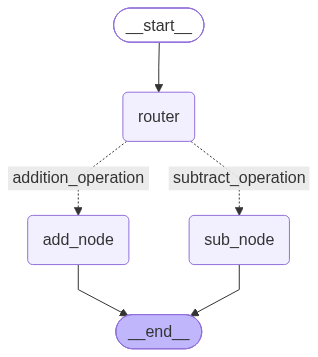

{'number1': 10, 'operation': '+', 'number2': 20, 'finalNumber': 30}


In [8]:
graph = StateGraph(AgentState)

graph.add_node("add_node",adder)
graph.add_node("sub_node",subtractor)
graph.add_node("router", lambda state:state)

graph.add_edge(START,"router")

graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        "addition_operation": "add_node",
        "subtract_operation": "sub_node"
    }
)

graph.add_edge("add_node",END)
graph.add_edge("sub_node",END)
app = graph.compile()

from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

initial_state_1 = AgentState(number1 = 10, operation="+",number2= 20)

print(app.invoke(initial_state_1))